<a href="https://colab.research.google.com/github/onishchenkoanastasia5-glitch/Machine_learning/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%9E%D0%BD%D0%B8%D1%89%D0%B5%D0%BD%D0%BA%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris(as_frame=True)

features_iris = iris.feature_names[:3]
X_iris = iris.data[features_iris]

print("Ознаки:", features_iris)
X_iris.head()

Ознаки: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']


,sepal length (cm),sepal width (cm),petal length (cm)
0,5.1,3.5,1.4
1,4.9,3.0,1.4
2,4.7,3.2,1.3
3,4.6,3.1,1.5
4,5.0,3.6,1.4


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

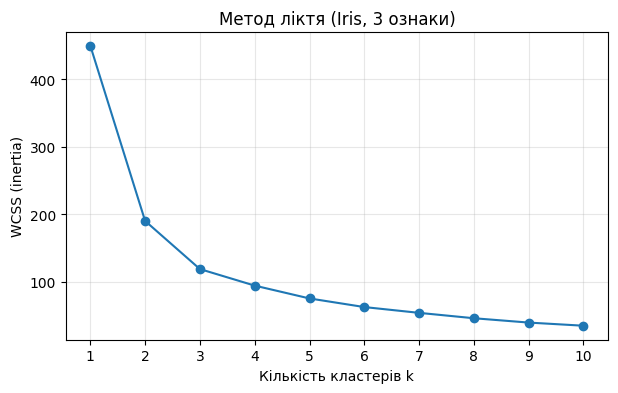

k=1: WCSS=450.0
k=2: WCSS=190.5
k=3: WCSS=119.1
k=4: WCSS=94.6
k=5: WCSS=75.6
k=6: WCSS=62.9
k=7: WCSS=54.3
k=8: WCSS=46.3
k=9: WCSS=39.9
k=10: WCSS=35.2


In [3]:
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

k_range = range(1, 11)
wcss_iris = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_iris_scaled)
    wcss_iris.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_range, wcss_iris, marker="o")
plt.title("Метод ліктя (Iris, 3 ознаки)")
plt.xlabel("Кількість кластерів k")
plt.ylabel("WCSS (inertia)")
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.show()

for k, w in zip(k_range, wcss_iris):
    print(f"k={k}: WCSS={w:.1f}")

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

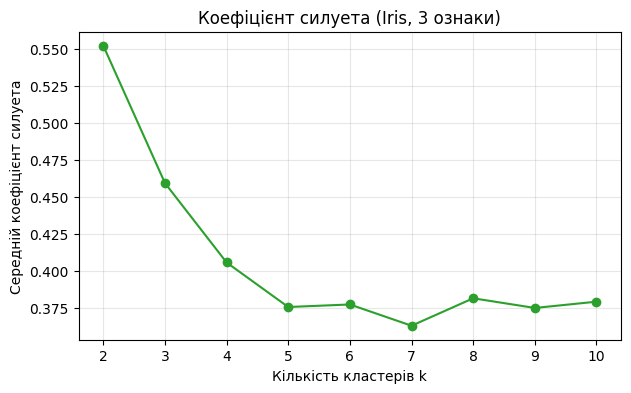

Найкращий k за силуетом: 2 (силует = 0.552)


In [4]:
sil_range = range(2, 11)
sil_iris = []
for k in sil_range:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_iris_scaled)
    sil_iris.append(silhouette_score(X_iris_scaled, labels))

plt.figure(figsize=(7, 4))
plt.plot(sil_range, sil_iris, marker="o", color="tab:green")
plt.title("Коефіцієнт силуета (Iris, 3 ознаки)")
plt.xlabel("Кількість кластерів k")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(list(sil_range))
plt.grid(alpha=0.3)
plt.show()

best_k_iris = list(sil_range)[sil_iris.index(max(sil_iris))]
print("Найкращий k за силуетом:", best_k_iris, f"(силует = {max(sil_iris):.3f})")

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

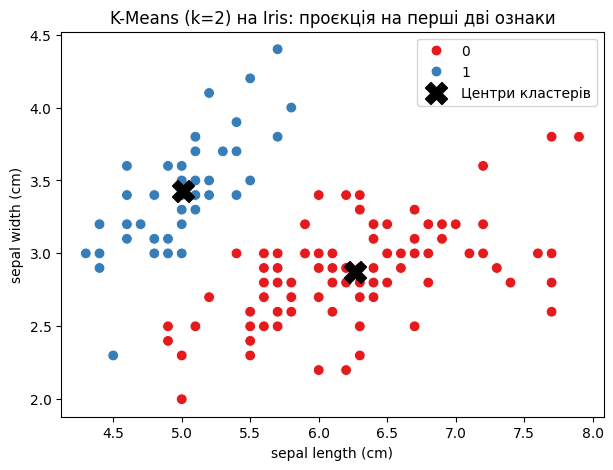

Розмір кластерів: {0: 100, 1: 50}
Силует для k=2: 0.552


In [5]:
kmeans_iris = KMeans(n_clusters=2, n_init=10, random_state=42)
labels_iris = kmeans_iris.fit_predict(X_iris_scaled)

centers_orig = scaler_iris.inverse_transform(kmeans_iris.cluster_centers_)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_iris.iloc[:, 0], y=X_iris.iloc[:, 1],
                hue=labels_iris, palette="Set1", s=60)
plt.scatter(centers_orig[:, 0], centers_orig[:, 1],
            c="black", marker="X", s=250, label="Центри кластерів")
plt.xlabel(features_iris[0])
plt.ylabel(features_iris[1])
plt.title("K-Means (k=2) на Iris: проєкція на перші дві ознаки")
plt.legend()
plt.show()

print("Розмір кластерів:", pd.Series(labels_iris).value_counts().sort_index().to_dict())
print("Силует для k=2:", round(silhouette_score(X_iris_scaled, labels_iris), 3))

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

**Відповідь.** Метод силуетів дає чіткий максимум при k = 2 (≈ 0,55), далі значення падає до ≈ 0,46 при k = 3 і залишається на рівні ≈ 0,37–0,41. На графіку ліктя WCSS різко зменшується від k = 1 до k = 2 (450 → ≈ 190), далі спад повільніший без різкого «зламу»; можливі й 2, і 3 кластери. Отже, вибір k = 2 підтверджується методом силуетів і є прийнятним за методом ліктя. Фізично це відповідає тому, що один вид (*setosa*) добре відокремлений, а *versicolor* та *virginica* частково перекриваються й K-Means об'єднує їх в один кластер.


## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [9]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [10]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [12]:
print(df.isnull().sum())
print("Усього пропусків:", df.isnull().sum().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64
Усього пропусків: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [13]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [15]:
X = df.drop(columns=["GradeClass", "StudentID"])
y = df["GradeClass"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, "Test:", X_test_scaled.shape)

Train: (1913, 13) Test: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [16]:
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42),
                       rf_params, cv=5, scoring="accuracy", n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

rf_best = rf_grid.best_estimator_
rf_cv = rf_grid.best_score_
rf_test = accuracy_score(y_test, rf_best.predict(X_test_scaled))

print("Найкращі параметри:", rf_grid.best_params_)
print(f"CV accuracy: {rf_cv:.4f}")
print(f"Test accuracy: {rf_test:.4f}")

Найкращі параметри: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
CV accuracy: 0.9211
Test accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [18]:
import warnings
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

lr_params = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
}
lr_grid = GridSearchCV(
    LogisticRegression(solver="saga", max_iter=5000, random_state=42),
    lr_params, cv=5, scoring="accuracy", n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)

lr_best = lr_grid.best_estimator_
lr_cv = lr_grid.best_score_
lr_test = accuracy_score(y_test, lr_best.predict(X_test_scaled))

print("Найкращі параметри:", lr_grid.best_params_)
print(f"CV accuracy: {lr_cv:.4f}")
print(f"Test accuracy: {lr_test:.4f}")

Найкращі параметри: {'C': 0.1, 'penalty': 'l1'}
CV accuracy: 0.8024
Test accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [19]:
svm_params = {
    "C": [0.1, 1, 10, 100],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", 0.01, 0.1],
}
svm_grid = GridSearchCV(SVC(random_state=42),
                        svm_params, cv=5, scoring="accuracy", n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)

svm_best = svm_grid.best_estimator_
svm_cv = svm_grid.best_score_
svm_test = accuracy_score(y_test, svm_best.predict(X_test_scaled))

print("Найкращі параметри:", svm_grid.best_params_)
print(f"CV accuracy: {svm_cv:.4f}")
print(f"Test accuracy: {svm_test:.4f}")

Найкращі параметри: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
CV accuracy: 0.8547
Test accuracy: 0.8497


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [20]:
results = pd.DataFrame({
    "Модель": ["Random Forest", "Logistic Regression", "SVM"],
    "CV accuracy": [rf_cv, lr_cv, svm_cv],
    "Test accuracy": [rf_test, lr_test, svm_test],
}).set_index("Модель")
display(results.round(4))

models = {"Random Forest": rf_best, "Logistic Regression": lr_best, "SVM": svm_best}
best_name = results["CV accuracy"].idxmax()   # вибір за CV, а не за тестом
print("\nНайкраща модель за CV-точністю:", best_name)

y_pred = models[best_name].predict(X_test_scaled)
print(classification_report(y_test, y_pred))

,CV accuracy,Test accuracy
Модель,,
Random Forest,0.9211,0.9102
Logistic Regression,0.8024,0.8184
SVM,0.8547,0.8497



Найкраща модель за CV-точністю: Random Forest
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

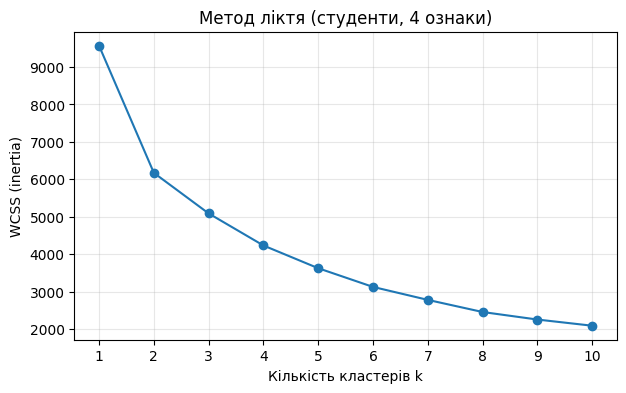

In [21]:
cluster_features = ["Age", "StudyTimeWeekly", "Absences", "GPA"]
X_stud_scaled = StandardScaler().fit_transform(df[cluster_features])

k_range = range(1, 11)
wcss_stud = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_stud_scaled)
    wcss_stud.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_range, wcss_stud, marker="o")
plt.title("Метод ліктя (студенти, 4 ознаки)")
plt.xlabel("Кількість кластерів k")
plt.ylabel("WCSS (inertia)")
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

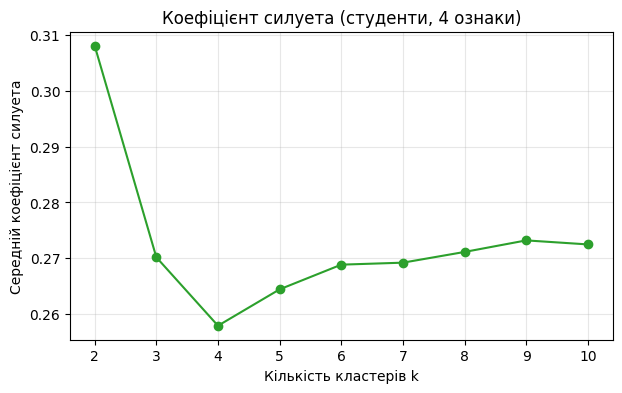

Найкращий k за силуетом: 2 (силует = 0.308)


In [22]:
sil_range = range(2, 11)
sil_stud = []
for k in sil_range:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_stud_scaled)
    sil_stud.append(silhouette_score(X_stud_scaled, labels))

plt.figure(figsize=(7, 4))
plt.plot(sil_range, sil_stud, marker="o", color="tab:green")
plt.title("Коефіцієнт силуета (студенти, 4 ознаки)")
plt.xlabel("Кількість кластерів k")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(list(sil_range))
plt.grid(alpha=0.3)
plt.show()

best_k_stud = list(sil_range)[sil_stud.index(max(sil_stud))]
print("Найкращий k за силуетом:", best_k_stud, f"(силует = {max(sil_stud):.3f})")

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [23]:
%pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [24]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [25]:
X_all = df.drop(columns=["StudentID", "GradeClass"])
print("Ознаки для PCA:", X_all.shape[1])
X_all.columns.tolist()

Ознаки для PCA: 13


['Age',
 'Gender',
 'Ethnicity',
 'ParentalEducation',
 'StudyTimeWeekly',
 'Absences',
 'Tutoring',
 'ParentalSupport',
 'Extracurricular',
 'Sports',
 'Music',
 'Volunteering',
 'GPA']

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [26]:
X_all_scaled = StandardScaler().fit_transform(X_all)

pca_full = PCA(random_state=42).fit(X_all_scaled)
explained = pca_full.explained_variance_ratio_

for i, v in enumerate(explained, start=1):
    print(f"PC{i}: {v:.4f}")

PC1: 0.1525
PC2: 0.0861
PC3: 0.0827
PC4: 0.0807
PC5: 0.0786
PC6: 0.0779
PC7: 0.0763
PC8: 0.0760
PC9: 0.0744
PC10: 0.0738
PC11: 0.0717
PC12: 0.0675
PC13: 0.0018


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Точка ліктя (кількість компонент): 2


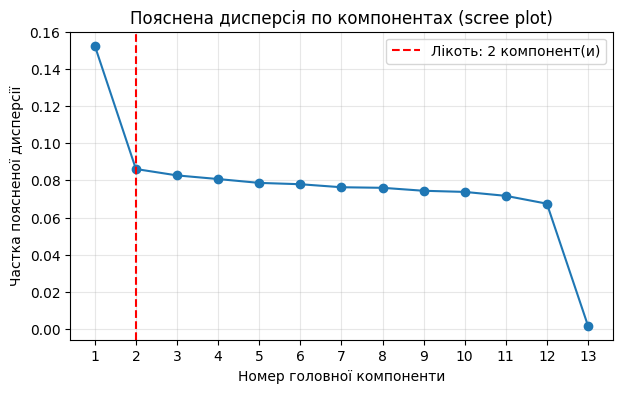

In [27]:
components = np.arange(1, len(explained) + 1)

kl = KneeLocator(components, explained, curve="convex", direction="decreasing")
n_components = int(kl.knee) if kl.knee is not None else 2
print("Точка ліктя (кількість компонент):", n_components)

plt.figure(figsize=(7, 4))
plt.plot(components, explained, marker="o")
plt.axvline(n_components, color="red", linestyle="--",
            label=f"Лікоть: {n_components} компонент(и)")
plt.title("Пояснена дисперсія по компонентах (scree plot)")
plt.xlabel("Номер головної компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(components)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

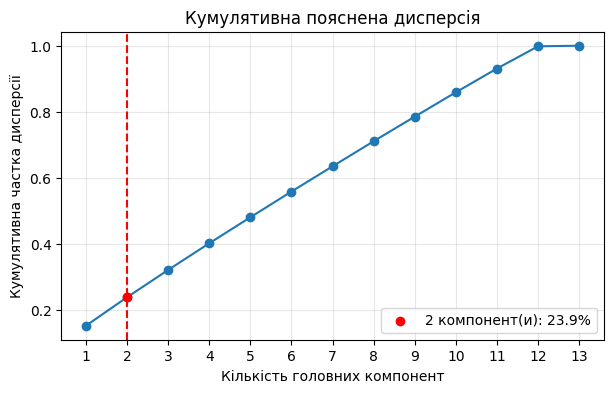

Обрано 2 компонент(и), пояснена частка дисперсії = 0.2386
Форма даних після PCA: (2392, 2)


In [28]:
cumulative = np.cumsum(explained)
chosen_var = cumulative[n_components - 1]

plt.figure(figsize=(7, 4))
plt.plot(components, cumulative, marker="o")
plt.axvline(n_components, color="red", linestyle="--")
plt.scatter([n_components], [chosen_var], color="red", zorder=5,
            label=f"{n_components} компонент(и): {chosen_var:.1%}")
plt.title("Кумулятивна пояснена дисперсія")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Кумулятивна частка дисперсії")
plt.xticks(components)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Обрано {n_components} компонент(и), пояснена частка дисперсії = {chosen_var:.4f}")

pca = PCA(n_components=n_components, random_state=42)
X_pca = pca.fit_transform(X_all_scaled)
print("Форма даних після PCA:", X_pca.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [29]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

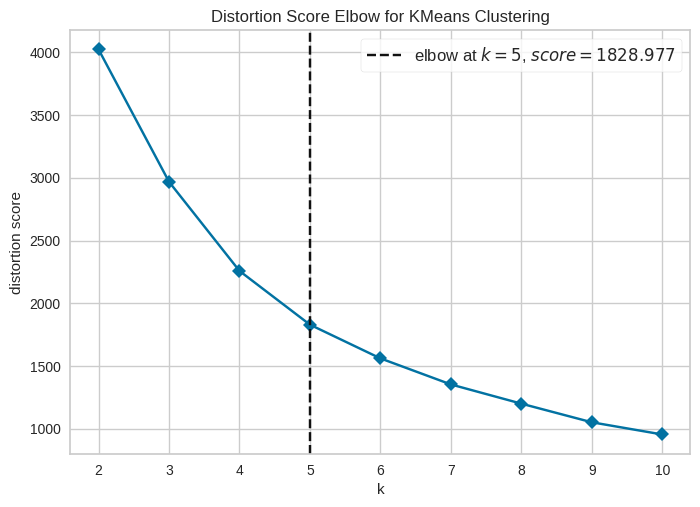

Оптимальне k за KElbowVisualizer: 5


In [30]:
visualizer = KElbowVisualizer(KMeans(n_init=10, random_state=42), k=(2, 11), timings=False, force_model=True)
visualizer.fit(X_pca)
visualizer.show()
print("Оптимальне k за KElbowVisualizer:", visualizer.elbow_value_)

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

*(Заповніть після запуску комірок, підставивши Ваші значення.)*

- **Iris:** метод силуетів вказує k = 2; метод ліктя допускає k = 2–3.
- **Студенти (4 ознаки):** метод ліктя — k = ___, метод силуетів — k = ___.
- **PCA:** обрано ___ головних компонент, що пояснюють ___ дисперсії; `KElbowVisualizer` після PCA дає k = ___.
- **Класифікація:** найкраща модель за CV — ___ (CV = ___, тест = ___).
- **Різниця задач:** класифікація навчається з учителем — модель вчиться передбачати відому мітку `GradeClass`. Кластеризація — навчання без учителя: мітки не використовуються, алгоритм групує студентів лише за схожістю ознак, тому кластери не мусять збігатися з класами оцінок.
